In [7]:
# ======================================
# SHAP Explainability
# ======================================

import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt
import re
import string
import nltk

from sklearn.model_selection import train_test_split

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

In [8]:
nltk.download("punkt")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [9]:
df = pd.read_csv("../data/processed/emails.csv")

print(df.head())

                                          subject  \
0                        Re: New Sequences Window   
1                       [zzzzteana] RE: Alexander   
2                       [zzzzteana] Moscow bomber   
3           [IRR] Klez: The Virus That  Won't Die   
4  Re: [zzzzteana] Nothing like mama used to make   

                                                body  label  
0      Date:        Wed, 21 Aug 2002 10:54:46 -05...      0  
1  Martin A posted:\nTassos Papadopoulos, the Gre...      0  
2  Man Threatens Explosion In Moscow \n\nThursday...      0  
3  Klez: The Virus That Won't Die\n \nAlready the...      0  
4  >  in adding cream to spaghetti carbonara, whi...      0  


In [12]:
df["subject"] = df["subject"].fillna("")
df["body"] = df["body"].fillna("")

df["text"] = df["subject"] + " " + df["body"]

In [15]:
def preprocess(text):

    text = str(text)
    text = text.lower()

    text = re.sub(r"http\S+|www\S+", "", text)

    text = text.translate(str.maketrans("", "", string.punctuation))

    words = word_tokenize(text)

    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word.isalpha() and word not in stop_words
    ]

    return " ".join(words)

In [16]:
df["clean_text"] = df["text"].apply(preprocess)

In [17]:
rf_model = joblib.load("../models/random_forest_tuned.pkl")

In [18]:
vectorizer = joblib.load("../models/tfidf_vectorizer.pkl")

In [19]:
X = vectorizer.transform(df["clean_text"])

y = df["label"]

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [29]:
import shap
import numpy as np

background = X_train[:100].toarray()
sample = X_test[:50].toarray()

In [30]:
explainer = shap.Explainer(
    rf_model,
    background
)

In [31]:
shap_values = explainer(sample)

In [32]:
shap.plots.beeswarm(shap_values, max_display=20)

ValueError: The beeswarm plot does not support plotting explanations with instances that have more than one dimension!

In [33]:
print(type(shap_values))

if hasattr(shap_values, "values"):
    print(shap_values.values.shape)

print(shap_values)

<class 'shap._explanation.Explanation'>
(50, 5000, 2)
.values =
array([[[ 0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00],
        ...,
        [ 0.00000000e+00,  0.00000000e+00],
        [-1.20450651e-04,  1.20450663e-04],
        [ 0.00000000e+00,  0.00000000e+00]],

       [[ 0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00],
        ...,
        [ 0.00000000e+00,  0.00000000e+00],
        [-7.54725824e-05,  7.54725833e-05],
        [ 0.00000000e+00,  0.00000000e+00]],

       [[ 0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00],
        ...,
        [ 0.00000000e+00,  0.00000000e+00],
        [-5.72474825e-05,  5.72474759e-05],
        [ 0.00000000e+00,  0.00000000e+00]],

       ...,

       [[ 0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00]

In [34]:
import shap

phishing_explanation = shap.Explanation(
    values=shap_values.values[:, :, 1],        # SHAP values for phishing class
    base_values=shap_values.base_values[:, 1], # Base values for phishing class
    data=shap_values.data,
    feature_names=shap_values.feature_names
)

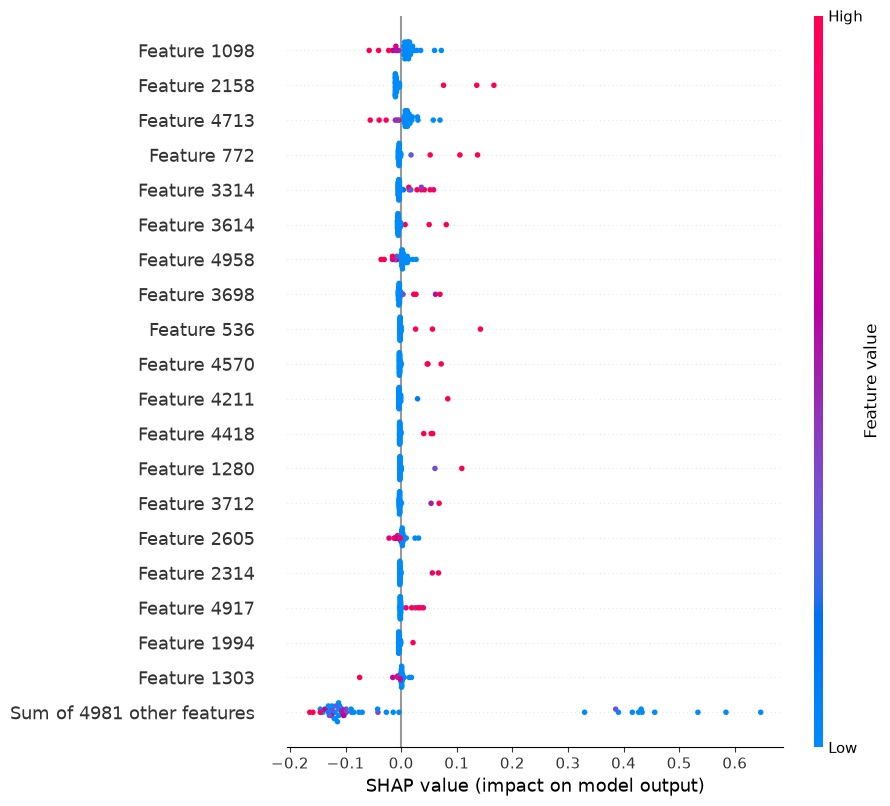

In [35]:
shap.plots.beeswarm(phishing_explanation, max_display=20)

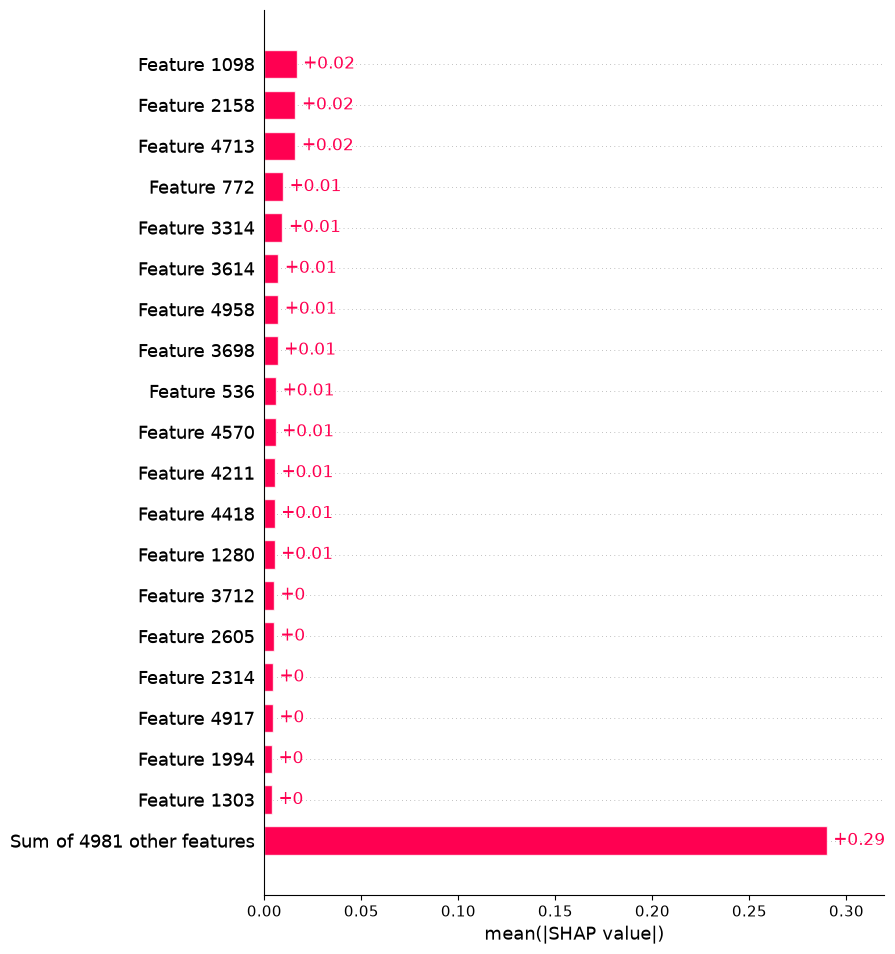

In [36]:
shap.plots.bar(phishing_explanation, max_display=20)

In [37]:
print(shap_values.base_values.shape)

(50, 2)
